In [1]:
# Load the Dataset
from sklearn.datasets import load_iris
iris = load_iris()


In [2]:
X,Y = iris.data, iris.target
print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [3]:
# Split the data
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=1)


In [4]:
X_train[:10]

array([[6.1, 3. , 4.6, 1.4],
       [7.7, 3. , 6.1, 2.3],
       [5.6, 2.5, 3.9, 1.1],
       [6.4, 2.8, 5.6, 2.1],
       [5.8, 2.8, 5.1, 2.4],
       [5.3, 3.7, 1.5, 0.2],
       [5.5, 2.3, 4. , 1.3],
       [5.2, 3.4, 1.4, 0.2],
       [6.5, 2.8, 4.6, 1.5],
       [6.7, 2.5, 5.8, 1.8]])

In [5]:
Y_train[:10]

array([1, 2, 1, 2, 2, 0, 1, 0, 1, 2])

In [6]:
for i, value in enumerate(iris.target_names):
    print(i, value)

0 setosa
1 versicolor
2 virginica


In [7]:

# Preprocessing
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
len(X_train),len(X_test),len(Y_train),len(Y_test)

(120, 30, 120, 30)

In [9]:
# Train a Classifier. Let's use a Logistic Regression
from sklearn.linear_model import LogisticRegression
clf_model = LogisticRegression(max_iter=200)
clf_model.fit(X_train, Y_train)

LogisticRegression(max_iter=200)

In [13]:
# Evaluate the Classifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
Y_pred = clf_model.predict(X_test)

In [14]:
print("Accuracy:",accuracy_score(Y_test,Y_pred))

Accuracy: 0.9666666666666667


In [15]:
print(Y_pred)
print(Y_test)

[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 2 0 2 1 0 0 1 2]
[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]


In [19]:
print("\nClassification Report:\n", classification_report(Y_test, Y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



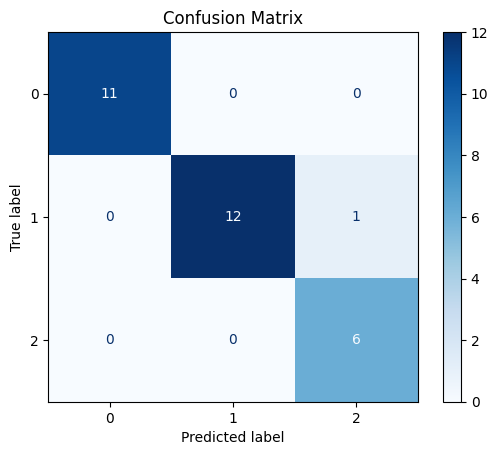

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report,ConfusionMatrixDisplay
cm_display = ConfusionMatrixDisplay(confusion_matrix(Y_test,Y_pred))
cm_display.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()



In [26]:
len(X_test)

30

In [27]:
print(Y_pred)
print(Y_test)

[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 2 0 2 1 0 0 1 2]
[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]


In [29]:
#Creating a Prediction Function
def predict_flower(sepal_length, sepal_width, petal_length, petal_width):
  sample = [[sepal_length, sepal_width, petal_length, petal_width]]
# Predict
  pred = clf_model.predict(sample)[0]
  species = iris.target_names
  prediction = f'The specie of flower is {species[pred]}'
  return prediction

In [30]:
print(predict_flower(5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [31]:
print(predict_flower(6.0, 3.0, 4.8, 1.8))

The specie of flower is virginica
